In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    auc,
    precision_recall_curve
)

In [2]:
df = pd.read_csv(
    "../data/processed/loan_data_feature_engineered.csv"
)

X = df.drop(columns=["Default"])
y = df["Default"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

## Load trained models

In [3]:
import joblib

logistic_model = joblib.load(
    "../models/logistic_baseline.pkl"
)

random_forest_model = joblib.load(
    "../models/random_forest_baseline.pkl"
)

xgb_model = joblib.load(
    "../models/xgboost_baseline.pkl"
)

In [4]:
y_prob_logistic = logistic_model.predict_proba(X_test)[:, 1]

y_prob_rf = random_forest_model.predict_proba(X_test)[:, 1]

y_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]

## Confusion matrices

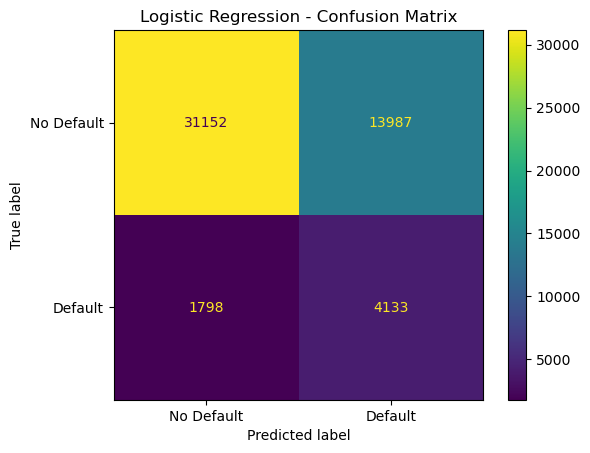

In [5]:
y_pred_logistic = (y_prob_logistic >= 0.5).astype(int)

cm_logistic = confusion_matrix(
    y_test,
    y_pred_logistic
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_logistic,
    display_labels=["No Default", "Default"]
)

disp.plot()
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

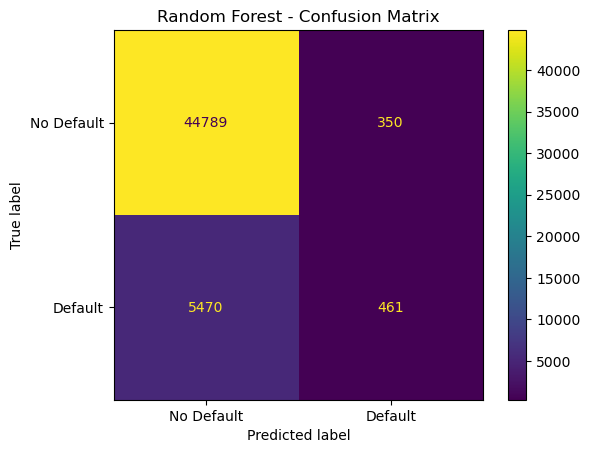

In [6]:
y_pred_rf = (y_prob_rf >= 0.5).astype(int)

cm_rf = confusion_matrix(
    y_test,
    y_pred_rf
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=["No Default", "Default"]
)

disp.plot()
plt.title("Random Forest - Confusion Matrix")
plt.show()

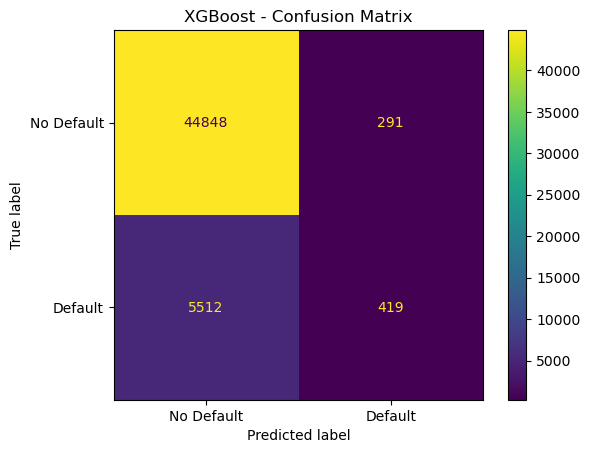

In [7]:
y_pred_xgb = (y_prob_xgb >= 0.5).astype(int)

cm_xgb = confusion_matrix(
    y_test,
    y_pred_xgb
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_xgb,
    display_labels=["No Default", "Default"]
)

disp.plot()
plt.title("XGBoost - Confusion Matrix")
plt.show()

## ROC Curve comparison

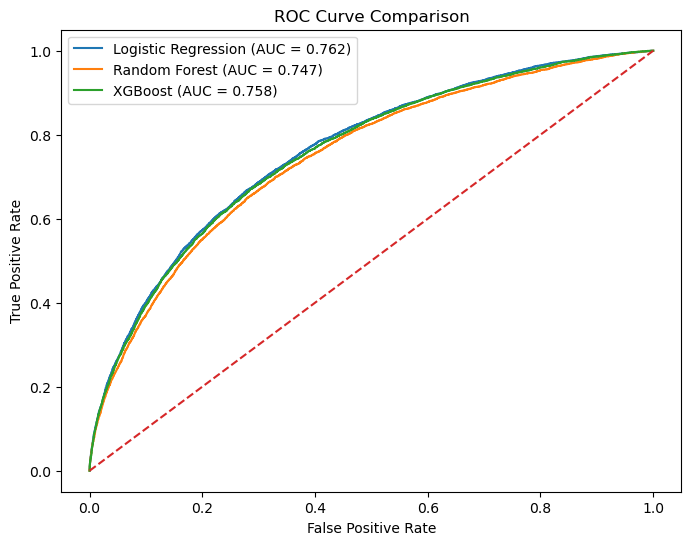

In [8]:
fpr_logistic, tpr_logistic, _ = roc_curve(
    y_test,
    y_prob_logistic
)

fpr_rf, tpr_rf, _ = roc_curve(
    y_test,
    y_prob_rf
)

fpr_xgb, tpr_xgb, _ = roc_curve(
    y_test,
    y_prob_xgb
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr_logistic,
    tpr_logistic,
    label=f"Logistic Regression (AUC = {auc(fpr_logistic, tpr_logistic):.3f})"
)

plt.plot(
    fpr_rf,
    tpr_rf,
    label=f"Random Forest (AUC = {auc(fpr_rf, tpr_rf):.3f})"
)

plt.plot(
    fpr_xgb,
    tpr_xgb,
    label=f"XGBoost (AUC = {auc(fpr_xgb, tpr_xgb):.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.show()

## Precision–Recall curves

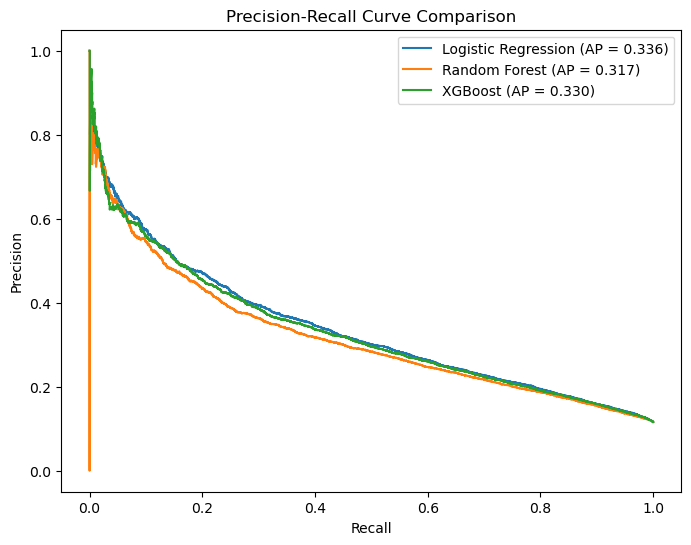

In [9]:
precision_logistic, recall_logistic, _ = precision_recall_curve(
    y_test,
    y_prob_logistic
)

precision_rf, recall_rf, _ = precision_recall_curve(
    y_test,
    y_prob_rf
)

precision_xgb, recall_xgb, _ = precision_recall_curve(
    y_test,
    y_prob_xgb
)

plt.figure(figsize=(8, 6))

plt.plot(
    recall_logistic,
    precision_logistic,
    label=f"Logistic Regression (AP = {average_precision_score(y_test, y_prob_logistic):.3f})"
)

plt.plot(
    recall_rf,
    precision_rf,
    label=f"Random Forest (AP = {average_precision_score(y_test, y_prob_rf):.3f})"
)

plt.plot(
    recall_xgb,
    precision_xgb,
    label=f"XGBoost (AP = {average_precision_score(y_test, y_prob_xgb):.3f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve Comparison")
plt.legend()
plt.show()

## Threshold tuning

In [10]:
thresholds = np.arange(
    0.10,
    0.91,
    0.05
)

threshold_results = []

for threshold in thresholds:

    predictions = (
        y_prob_logistic >= threshold
    ).astype(int)

    precision = precision_score(
        y_test,
        predictions,
        zero_division=0
    )

    recall = recall_score(
        y_test,
        predictions,
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        predictions,
        zero_division=0
    )

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    })

threshold_df = pd.DataFrame(
    threshold_results
)

threshold_df

,Threshold,Precision,Recall,F1
0,0.10,0.119039,0.996122,0.212663
1,0.15,0.125356,0.987692,0.222475
2,0.20,0.133729,0.971506,0.235097
3,0.25,0.143604,0.944866,0.249316
4,0.30,0.155668,0.909965,0.265856
5,0.35,0.170809,0.870174,0.285564
6,0.40,0.187592,0.820266,0.305351
7,0.45,0.206702,0.765470,0.325506
8,0.50,0.228091,0.696847,0.343686
9,0.55,0.252743,0.621480,0.359347


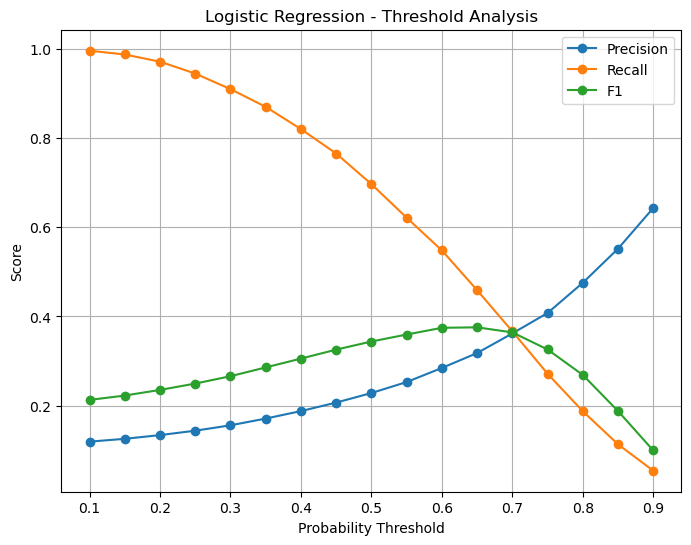

In [11]:
plt.figure(figsize=(8, 6))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1"],
    marker="o",
    label="F1"
)

plt.xlabel("Probability Threshold")
plt.ylabel("Score")
plt.title("Logistic Regression - Threshold Analysis")
plt.legend()
plt.grid()
plt.show()

## Find the best F1 threshold

In [12]:
best_threshold_row = threshold_df.loc[
    threshold_df["F1"].idxmax()
]

best_threshold_row

Threshold    0.650000
Precision    0.317768
Recall       0.458945
F1           0.375526
Name: 11, dtype: float64

In [13]:
best_threshold = best_threshold_row["Threshold"]

best_threshold

np.float64(0.6500000000000001)

In [14]:
y_pred_tuned = (
    y_prob_logistic >= best_threshold
).astype(int)

print(
    "Precision:",
    precision_score(
        y_test,
        y_pred_tuned
    )
)

print(
    "Recall:",
    recall_score(
        y_test,
        y_pred_tuned
    )
)

print(
    "F1:",
    f1_score(
        y_test,
        y_pred_tuned
    )
)

Precision: 0.31776791968246554
Recall: 0.45894452874726016
F1: 0.3755259708905291


## threshold analysis for XGBoost

In [15]:
threshold_results_xgb = []

for threshold in thresholds:

    predictions = (
        y_prob_xgb >= threshold
    ).astype(int)

    precision = precision_score(
        y_test,
        predictions,
        zero_division=0
    )

    recall = recall_score(
        y_test,
        predictions,
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        predictions,
        zero_division=0
    )

    threshold_results_xgb.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    })

threshold_df_xgb = pd.DataFrame(
    threshold_results_xgb
)

threshold_df_xgb

,Threshold,Precision,Recall,F1
0,0.10,0.211201,0.738830,0.328498
1,0.15,0.267128,0.579160,0.365620
2,0.20,0.319671,0.445793,0.372342
3,0.25,0.363821,0.332659,0.347543
4,0.30,0.416690,0.251728,0.313853
5,0.35,0.463715,0.190693,0.270251
6,0.40,0.516288,0.141629,0.222281
7,0.45,0.560229,0.098803,0.167981
8,0.50,0.590141,0.070646,0.126186
9,0.55,0.633406,0.049233,0.091364


In [16]:
best_xgb_row = threshold_df_xgb.loc[
    threshold_df_xgb["F1"].idxmax()
]

best_xgb_row

Threshold    0.200000
Precision    0.319671
Recall       0.445793
F1           0.372342
Name: 2, dtype: float64

## XGBoost class imbalance

In [19]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    auc,
    precision_recall_curve
)

In [17]:
class_counts = y_train.value_counts()

negative = class_counts[0]
positive = class_counts[1]

scale_pos_weight = negative / positive

scale_pos_weight

np.float64(7.61128909872692)

In [21]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

# Identify feature types
numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

# Recreate the preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)

# Calculate class imbalance ratio
class_counts = y_train.value_counts()

negative = class_counts[0]
positive = class_counts[1]

scale_pos_weight = negative / positive

print("Negative samples:", negative)
print("Positive samples:", positive)
print("Scale Pos Weight:", scale_pos_weight)

# XGBoost with class imbalance handling
xgb_balanced = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "classifier",
            XGBClassifier(
                n_estimators=300,
                max_depth=6,
                learning_rate=0.05,
                subsample=0.8,
                colsample_bytree=0.8,
                scale_pos_weight=scale_pos_weight,
                eval_metric="logloss",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

# Train
xgb_balanced.fit(X_train, y_train)

print("XGBoost Balanced training completed.")

Negative samples: 180555
Positive samples: 23722
Scale Pos Weight: 7.61128909872692
XGBoost Balanced training completed.


In [22]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# Predictions
y_pred_xgb_balanced = xgb_balanced.predict(X_test)

# Default probabilities
y_prob_xgb_balanced = xgb_balanced.predict_proba(X_test)[:, 1]

# Evaluation
xgb_balanced_results = {
    "Accuracy": accuracy_score(y_test, y_pred_xgb_balanced),
    "Precision": precision_score(y_test, y_pred_xgb_balanced),
    "Recall": recall_score(y_test, y_pred_xgb_balanced),
    "F1": f1_score(y_test, y_pred_xgb_balanced),
    "ROC-AUC": roc_auc_score(y_test, y_prob_xgb_balanced),
    "PR-AUC": average_precision_score(y_test, y_prob_xgb_balanced)
}

xgb_balanced_results

{'Accuracy': 0.7087918543176033,
 'Precision': 0.23451511372409287,
 'Recall': 0.6658236385095262,
 'F1': 0.3468599033816425,
 'ROC-AUC': np.float64(0.7569059365434353),
 'PR-AUC': np.float64(0.3300379473993999)}

In [23]:
xgb_balanced.fit(
    X_train,
    y_train
)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Age', 'Income',
                                                   'LoanAmount', 'CreditScore',
                                                   'MonthsEmployed',
                                                   'NumCreditLines',
                                                   'InterestRate', 'LoanTerm',
                                                   'DTIRatio',
                                                   'LoanToIncomeRatio']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Education',
                                                   'EmploymentType',
                                                   'MaritalStatus',
                                                   'HasMortgage',
                                                   'HasDependents',
                                                   'Loa...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.05,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=6, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=300, n_jobs=-1,
                               num_parallel_tree=None, ...))])

In [25]:
y_pred_xgb_balanced = xgb_balanced.predict(
    X_test
)

y_prob_xgb_balanced = (
    xgb_balanced.predict_proba(X_test)[:, 1]
)

In [26]:
xgb_balanced_results = {
    "Accuracy": accuracy_score(
        y_test,
        y_pred_xgb_balanced
    ),

    "Precision": precision_score(
        y_test,
        y_pred_xgb_balanced
    ),

    "Recall": recall_score(
        y_test,
        y_pred_xgb_balanced
    ),

    "F1": f1_score(
        y_test,
        y_pred_xgb_balanced
    ),

    "ROC-AUC": roc_auc_score(
        y_test,
        y_prob_xgb_balanced
    ),

    "PR-AUC": average_precision_score(
        y_test,
        y_prob_xgb_balanced
    )
}

xgb_balanced_results

{'Accuracy': 0.7087918543176033,
 'Precision': 0.23451511372409287,
 'Recall': 0.6658236385095262,
 'F1': 0.3468599033816425,
 'ROC-AUC': np.float64(0.7569059365434353),
 'PR-AUC': np.float64(0.3300379473993999)}

In [28]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# Predictions at default threshold = 0.5
y_pred_logistic = (y_prob_logistic >= 0.5).astype(int)
y_pred_rf = (y_prob_rf >= 0.5).astype(int)
y_pred_xgb = (y_prob_xgb >= 0.5).astype(int)

# Calculate Logistic Regression metrics
logistic_results = {
    "Accuracy": accuracy_score(y_test, y_pred_logistic),
    "Precision": precision_score(y_test, y_pred_logistic),
    "Recall": recall_score(y_test, y_pred_logistic),
    "F1": f1_score(y_test, y_pred_logistic),
    "ROC-AUC": roc_auc_score(y_test, y_prob_logistic),
    "PR-AUC": average_precision_score(y_test, y_prob_logistic)
}

# Calculate Random Forest metrics
rf_results = {
    "Accuracy": accuracy_score(y_test, y_pred_rf),
    "Precision": precision_score(y_test, y_pred_rf),
    "Recall": recall_score(y_test, y_pred_rf),
    "F1": f1_score(y_test, y_pred_rf),
    "ROC-AUC": roc_auc_score(y_test, y_prob_rf),
    "PR-AUC": average_precision_score(y_test, y_prob_rf)
}

# Calculate XGBoost metrics
xgb_results = {
    "Accuracy": accuracy_score(y_test, y_pred_xgb),
    "Precision": precision_score(y_test, y_pred_xgb),
    "Recall": recall_score(y_test, y_pred_xgb),
    "F1": f1_score(y_test, y_pred_xgb),
    "ROC-AUC": roc_auc_score(y_test, y_prob_xgb),
    "PR-AUC": average_precision_score(y_test, y_prob_xgb)
}

# Create comparison table
results_phase5 = pd.DataFrame(
    [
        logistic_results,
        rf_results,
        xgb_results,
        xgb_balanced_results
    ],
    index=[
        "Logistic Regression",
        "Random Forest",
        "XGBoost",
        "XGBoost Balanced"
    ]
)

results_phase5

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Logistic Regression,0.690914,0.228091,0.696847,0.343686,0.761595,0.336248
Random Forest,0.886039,0.568434,0.077727,0.136755,0.747229,0.316855
XGBoost,0.886372,0.590141,0.070646,0.126186,0.757581,0.330254
XGBoost Balanced,0.708792,0.234515,0.665824,0.346860,0.756906,0.330038


In [29]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

thresholds = np.arange(0.10, 0.91, 0.05)


def evaluate_thresholds(y_true, y_prob):

    results = []

    for threshold in thresholds:

        y_pred = (y_prob >= threshold).astype(int)

        precision = precision_score(
            y_true,
            y_pred,
            zero_division=0
        )

        recall = recall_score(
            y_true,
            y_pred,
            zero_division=0
        )

        f1 = f1_score(
            y_true,
            y_pred,
            zero_division=0
        )

        results.append({
            "Threshold": threshold,
            "Precision": precision,
            "Recall": recall,
            "F1": f1
        })

    return pd.DataFrame(results)

In [30]:
threshold_logistic = evaluate_thresholds(
    y_test,
    y_prob_logistic
)

threshold_rf = evaluate_thresholds(
    y_test,
    y_prob_rf
)

threshold_xgb = evaluate_thresholds(
    y_test,
    y_prob_xgb
)

threshold_xgb_balanced = evaluate_thresholds(
    y_test,
    y_prob_xgb_balanced
)

In [31]:
best_logistic = threshold_logistic.loc[
    threshold_logistic["F1"].idxmax()
]

best_rf = threshold_rf.loc[
    threshold_rf["F1"].idxmax()
]

best_xgb = threshold_xgb.loc[
    threshold_xgb["F1"].idxmax()
]

best_xgb_balanced = threshold_xgb_balanced.loc[
    threshold_xgb_balanced["F1"].idxmax()
]

In [32]:
threshold_comparison = pd.DataFrame(
    [
        best_logistic,
        best_rf,
        best_xgb,
        best_xgb_balanced
    ],
    index=[
        "Logistic Regression",
        "Random Forest",
        "XGBoost",
        "XGBoost Balanced"
    ]
)

threshold_comparison

,Threshold,Precision,Recall,F1
Logistic Regression,0.65,0.317768,0.458945,0.375526
Random Forest,0.25,0.299206,0.450851,0.359699
XGBoost,0.20,0.319671,0.445793,0.372342
XGBoost Balanced,0.65,0.324657,0.435340,0.371939
